# Part 7: homelessness (AHAR) as context for the affordable-housing picture

HUD's Annual Homeless Assessment Report publishes a one-night **Point-in-Time (PIT) count** each January and a **Housing Inventory Count (HIC)** of beds. This section uses them as **context**, not as a forecast: how many people are
counted, where, how that relates to the need measures from Parts 1 to 6, and how much supportive housing exists. It is deliberately descriptive. The earlier quick test (and the regression below) found that annual changes in state rents do not explain annual
changes in state homelessness once state and year effects are included, so no projection of homelessness is attempted.

**Data limits that apply throughout.** The PIT is a single night and undercounts people doubled up. The unsheltered count is incomplete in **2021** (all states, COVID) and in **2024** for nine states named in HUD's footnote (AL, AR, CA, CO, FL, MD, NJ, OR, TX), so those state-years are flagged and
left out of the regressions. The 51 geographies exclude territories (their sum is 767,856 for 2024 against HUD's 771,480).

In [1]:
import sys, warnings
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from linearmodels.panel import PanelOLS
from IPython.display import display

from viz import apply_style, SERIES, save_figure, SURFACE, MUTED, BASELINE, INK_2, dot, tile_map, SEQUENTIAL

apply_style()
pd.set_option("display.width", 220)
panel = pd.read_csv("data/processed/panel.csv", dtype={"state_fips": str})
abbr = panel.groupby("state_fips").state_abbr.first()
names = panel.groupby("state_fips").state_name.first()
panel["state"] = panel.state_fips.map(abbr)

## 1. The national count

In [2]:
nat = panel[panel.year.between(2010, 2024)].groupby("year")[["pit_overall", "pit_sheltered", "pit_unsheltered", "pit_chronic_people"]].sum(min_count=1)
flag = panel.groupby("year").unsheltered_incomplete.sum()
display(nat.assign(states_with_incomplete_unsheltered=flag).astype("Int64").T)
fig, ax = plt.subplots(figsize=(18, 10))
yrs = nat.index
ax.axvspan(2020.5, 2021.5, color="#ecebe6", zorder=0)
ax.text(2021, nat.pit_overall.max() * 1.03, "2021: unsheltered\ncount incomplete", ha="center", fontsize=8, color=MUTED, va="bottom")
for col, lab, c in (("pit_overall", "all people counted", SERIES[0]), ("pit_sheltered", "sheltered", SERIES[2]), ("pit_unsheltered", "unsheltered", SERIES[1])):
    ax.plot(yrs, nat[col] / 1000, color=c)
    for x, v in zip(yrs, nat[col]):
        dot(ax, x, v / 1000, c)
    ax.annotate(lab, (yrs[-1], nat[col].iloc[-1] / 1000), xytext=(8, 0), textcoords="offset points", fontsize=9, color=INK_2, va="center")
ax.set_xlim(2009.5, 2026.4); ax.set_ylabel("people counted on one January night, thousands")
ax.set_title(f"The count fell to 2016, rose to 2020, then jumped: {nat.pit_overall[2023] / 1000:.0f}k in 2023 and {nat.pit_overall[2024] / 1000:.0f}k in 2024", fontsize=11, loc="left")
fig.tight_layout()
save_figure(fig, "71_national_trend", part="07_homelessness")
plt.show()
chg = nat.loc[2024] - nat.loc[2023]
print(f"2023 to 2024: all +{chg.pit_overall:,.0f} ({chg.pit_overall / nat.pit_overall[2023]:.0%}), sheltered +{chg.pit_sheltered:,.0f}, unsheltered +{chg.pit_unsheltered:,.0f}; 2016 to 2023: all {nat.pit_overall[2023] - nat.pit_overall[2016]:+,.0f}")

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
pit_overall,630806,618611,616556,584483,570514,558573,544084,545566,547264,562184,575714,379813,577778,649535,767856
pit_sheltered,401865,390924,388516,393049,399434,389847,372049,359669,357365,355574,353653,325422,347872,395801,496506
pit_unsheltered,228941,227687,228040,191434,171080,168726,172035,185897,189899,206610,222061,54391,229906,253734,271350
pit_chronic_people,<NA>,114904,108367,100321,96914,94344,84279,93616,95449,104666,119466,64186,138042,153932,167410
states_with_incomplete_unsheltered,0,0,0,0,0,0,0,0,0,0,0,51,0,0,9


2023 to 2024: all +118,321 (18%), sheltered +100,705, unsheltered +17,616; 2016 to 2023: all +105,451


## 2. Where the recent rise happened

The 2023 to 2024 change by state (counts, sheltered and unsheltered). Nine states have incomplete unsheltered counts in 2024, so the unsheltered change is a floor for them.

In [3]:
w = panel[panel.year.isin([2023, 2024])].pivot(index="state", columns="year", values=["pit_overall", "pit_sheltered", "pit_unsheltered"])
ch = pd.DataFrame({"all": w["pit_overall"][2024] - w["pit_overall"][2023], "sheltered": w["pit_sheltered"][2024] - w["pit_sheltered"][2023], "unsheltered": w["pit_unsheltered"][2024] - w["pit_unsheltered"][2023], "2023": w["pit_overall"][2023], "2024": w["pit_overall"][2024]})
ch["pct"] = 100 * ch["all"] / ch["2023"]
top = ch.sort_values("all", ascending=False).head(8)
display(top.round(1))
share_top5 = ch.sort_values("all", ascending=False).head(5)["all"].sum() / ch["all"].sum()
print(f"the five largest increases ({', '.join(ch.sort_values('all', ascending=False).head(5).index)}) account for {share_top5:.0%} of the national increase; states with a decrease: {int((ch['all'] < 0).sum())} of 51")

,all,sheltered,unsheltered,2023,2024,pct
state,,,,,,
NY,54819.0,54188.0,631.0,103200.0,158019.0,53.1
IL,13885.0,12840.0,1045.0,11947.0,25832.0,116.2
MA,10219.0,9946.0,273.0,19141.0,29360.0,53.4
CA,5685.0,5134.0,551.0,181399.0,187084.0,3.1
HI,5414.0,5279.0,135.0,6223.0,11637.0,87.0
CO,4276.0,4230.0,46.0,14439.0,18715.0,29.6
WA,3518.0,1249.0,2269.0,28036.0,31554.0,12.5
OR,2733.0,1546.0,1187.0,20142.0,22875.0,13.6


the five largest increases (NY, IL, MA, CA, HI) account for 76% of the national increase; states with a decrease: 7 of 51


## 3. Levels across states and their link to the need measures

Cross-section for **2023** (complete in every state). Rank correlations between the PIT rate per 10,000 residents and the measures built in earlier parts: rent as a share of income, the severe burden, the need index (AHNI), affordable units per 100 ELI renters,
assisted units per eligible renter, and ELI renters. Spearman, 51 states.

In [4]:
a23 = panel[panel.year == 2023].set_index("state")
ahni = pd.read_csv("outputs/tables/ahni_ranking.csv", index_col=0)      # indexed by state abbreviation
pm = pd.read_csv("outputs/tables/policy_metrics.csv", index_col=0)
stake = pd.read_csv("outputs/tables/units_at_stake_state.csv", dtype={"state_fips": str}).set_index("state")
chas = pd.read_csv("data/interim/chas_state_vintage.csv", dtype={"state_fips": str})
chas = chas[chas.chas_vintage == "2018-2022"].set_index("state_fips")
d = pd.DataFrame({"pit_rate": a23.pit_rate_per_10k, "unsheltered_rate": a23.pit_unsheltered_rate_per_10k,
                  "rent_to_income": a23.rent_to_income_pct, "severe_burden": a23.severe_rent_burden_pct, "median_rent": a23.median_gross_rent,
                  "vacancy": a23.rental_vacancy_rate_pct, "psh_beds_per_10k": a23.hic_psh_beds_per_10k, "shelter_beds_per_10k": a23.hic_shelter_beds_per_10k})
d["ahni_rank"] = d.index.map(ahni.ahni_rank)
d["afford_per100_eli"] = d.index.map(lambda s: chas.chas_affordable_units_per100_eli.get(panel[panel.state == s].state_fips.iloc[0]))
d["assisted_per100"] = d.index.map(lambda s: pm["assisted units per 100 eligible renters"].get(s))
d["stake_per100_eli"] = d.index.map(lambda s: stake.stake_per100_eli.get(s))
rows = []
for col, lab in (("rent_to_income", "rent as a share of income"), ("median_rent", "median gross rent"), ("severe_burden", "severe rent burden"), ("ahni_rank", "need index rank (1 = highest need)"), ("afford_per100_eli", "affordable units per 100 ELI renters"),
                 ("assisted_per100", "assisted units per 100 eligible renters"), ("vacancy", "rental vacancy rate"), ("psh_beds_per_10k", "supportive housing beds per 10,000"), ("stake_per100_eli", "units at stake by 2035 per 100 ELI renters")):
    x = d[[col, "pit_rate"]].dropna()
    r, p = stats.spearmanr(x[col], x.pit_rate)
    x2 = x.drop(index="DC", errors="ignore"); r2, p2 = stats.spearmanr(x2[col], x2.pit_rate)
    rows.append({"measure": lab, "rank correlation with PIT rate": r, "p": p, "without DC": r2, "p without DC": p2})
cor = pd.DataFrame(rows).set_index("measure")
display(cor.round(2))

,rank correlation with PIT rate,p,without DC,p without DC
measure,,,,
rent as a share of income,0.37,0.01,0.35,0.01
median gross rent,0.58,0.00,0.55,0.00
severe rent burden,0.17,0.23,0.20,0.16
need index rank (1 = highest need),-0.33,0.02,-0.37,0.01
affordable units per 100 ELI renters,-0.22,0.12,-0.21,0.15
assisted units per 100 eligible renters,-0.01,0.92,-0.08,0.60
rental vacancy rate,-0.36,0.01,-0.34,0.02
"supportive housing beds per 10,000",0.61,0.00,0.58,0.00
units at stake by 2035 per 100 ELI renters,-0.06,0.68,-0.07,0.64


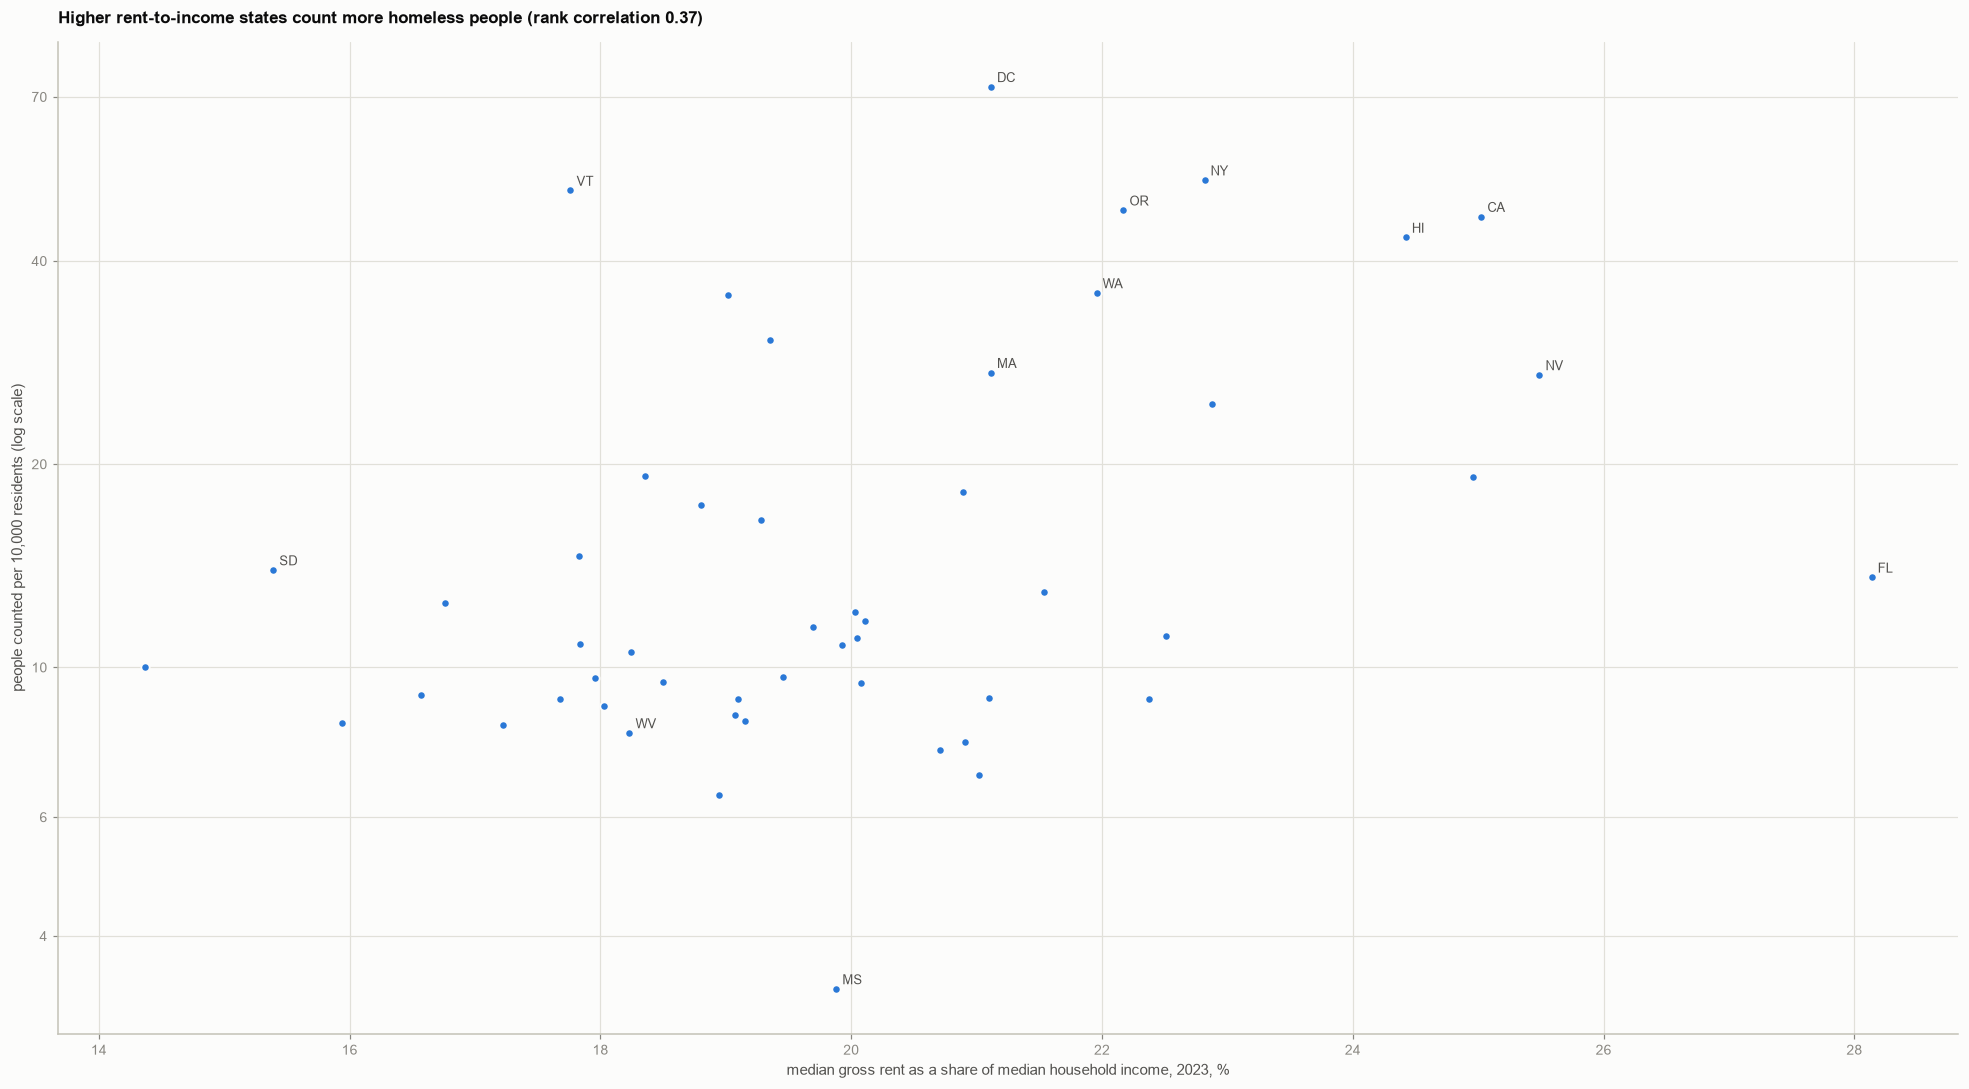

In [5]:
fig, ax = plt.subplots(figsize=(18, 10))
x = d.dropna(subset=["rent_to_income", "pit_rate"])
ax.scatter(x.rent_to_income, x.pit_rate, s=30, color=SERIES[0], edgecolor=SURFACE, linewidth=1.2, zorder=3)
ax.set_yscale("log"); ax.set_yticks([4, 6, 10, 20, 40, 70]); ax.set_yticklabels(["4", "6", "10", "20", "40", "70"]); ax.minorticks_off()
for s in ["DC", "NY", "HI", "CA", "OR", "WA", "MA", "NV", "FL", "WV", "MS", "SD", "VT"]:
    if s in x.index:
        ax.annotate(s, (x.loc[s, "rent_to_income"], x.loc[s, "pit_rate"]), xytext=(4, 3), textcoords="offset points", fontsize=8.5, color=INK_2)
ax.set_xlabel("median gross rent as a share of median household income, 2023, %"); ax.set_ylabel("people counted per 10,000 residents (log scale)")
r = cor.loc["rent as a share of income", "rank correlation with PIT rate"]
ax.set_title(f"Higher rent-to-income states count more homeless people (rank correlation {r:.2f})", fontsize=11, loc="left")
fig.tight_layout()
save_figure(fig, "71_rent_vs_pit", part="07_homelessness")
plt.show()

## 4. Levels versus changes

The cross-state pattern above is about levels. The question for the future is about **changes**: if a state's rent rises, does its count rise? Two-way fixed effects (state and year) on the log PIT rate, errors clustered by state, 2010 to 2024 with the flagged
state-years left out. The between-state version uses state means over 2022 and 2023 with robust errors.

In [6]:
q = panel[panel.year.between(2010, 2024) & (panel.unsheltered_incomplete == 0)].copy()
q["ly"] = np.log(q.pit_rate_per_10k); q["lshel"] = np.log((q.pit_sheltered / q.population) * 1e4)
q["lrent"] = np.log(q.median_gross_rent); q["linc"] = np.log(q.median_hh_income)
x = q.dropna(subset=["ly", "lshel", "lrent", "linc", "rental_vacancy_rate_pct", "unemployment_rate_pct"]).set_index(["state_fips", "year"])
rows = []
for lab, y in (("all people counted", "ly"), ("sheltered only", "lshel")):
    for spec, cols in (("rent and income", ["lrent", "linc"]), ("plus vacancy and unemployment", ["lrent", "linc", "rental_vacancy_rate_pct", "unemployment_rate_pct"])):
        m = PanelOLS(x[y], x[cols], entity_effects=True, time_effects=True).fit(cov_type="clustered", cluster_entity=True)
        rows.append({"outcome": lab, "model": spec, "state-years": int(m.nobs), "log rent coef": m.params["lrent"], "t (rent)": m.tstats["lrent"], "log income coef": m.params["linc"], "t (income)": m.tstats["linc"]})
within = pd.DataFrame(rows)
display(within.round(2))
b = q[q.year.isin([2022, 2023])].groupby("state_fips")[["ly", "lrent", "linc", "rental_vacancy_rate_pct", "unemployment_rate_pct"]].mean()
mb = sm.OLS(b.ly, sm.add_constant(b[["lrent", "linc"]])).fit(cov_type="HC3")
print(f"between states (means of 2022-23, n = {len(b)}): log rent {mb.params['lrent']:.2f} (t {mb.tvalues['lrent']:.1f}), log income {mb.params['linc']:.2f} (t {mb.tvalues['linc']:.1f})")

,outcome,model,state-years,log rent coef,t (rent),log income coef,t (income)
0,all people counted,rent and income,654,-0.17,-0.30,1.47,1.82
1,all people counted,plus vacancy and unemployment,654,-0.46,-0.82,2.08,2.58
2,sheltered only,rent and income,654,-0.24,-0.43,0.35,0.43
3,sheltered only,plus vacancy and unemployment,654,-0.49,-0.85,0.97,1.13


between states (means of 2022-23, n = 51): log rent 1.48 (t 2.9), log income 0.30 (t 0.4)


## 5. Supportive housing and chronic homelessness

Permanent supportive housing (PSH) beds from the HIC against people counted as chronically homeless (2023). This is a snapshot ratio, not a need estimate: PSH beds serve people who left homelessness earlier, and many people counted are not chronically homeless.

In [7]:
c23 = panel[panel.year == 2023].set_index("state")
s = pd.DataFrame({"chronic_people": c23.pit_chronic_people, "psh_beds": c23.hic_beds_psh, "pit_rate": c23.pit_rate_per_10k, "unsheltered_share": 100 * c23.pit_unsheltered / c23.pit_overall})
s["psh_beds_per_chronic"] = s.psh_beds / s.chronic_people
display(s.sort_values("psh_beds_per_chronic").head(6).round(2))
display(s.sort_values("psh_beds_per_chronic").tail(4).round(2))
print(f"national 2023: {s.psh_beds.sum():,.0f} PSH beds for {s.chronic_people.sum():,.0f} chronically homeless people counted ({s.psh_beds.sum() / s.chronic_people.sum():.1f} beds per person); median state {s.psh_beds_per_chronic.median():.1f}")
r_sup = stats.spearmanr(s.dropna().psh_beds_per_chronic, s.dropna().unsheltered_share)
print(f"states with fewer PSH beds per chronically homeless person have a higher unsheltered share: rank correlation {r_sup[0]:.2f} (p {r_sup[1]:.3f})")

,chronic_people,psh_beds,pit_rate,unsheltered_share,psh_beds_per_chronic
state,,,,,
CA,71150.0,75100.0,46.55,68.04,1.06
OK,1403.0,1815.0,11.47,40.99,1.29
NV,2433.0,3150.0,27.13,52.56,1.29
OR,6748.0,8940.0,47.58,64.56,1.32
VT,249.0,330.0,50.89,4.16,1.33
AR,888.0,1181.0,8.50,50.67,1.33


,chronic_people,psh_beds,pit_rate,unsheltered_share,psh_beds_per_chronic
state,,,,,
DC,1354.0,15349.0,72.49,16.76,11.34
LA,442.0,5888.0,6.93,44.15,13.32
OH,1232.0,19055.0,9.66,21.10,15.47
CT,119.0,7392.0,8.34,16.62,62.12


national 2023: 393,752 PSH beds for 153,932 chronically homeless people counted (2.6 beds per person); median state 3.1
states with fewer PSH beds per chronically homeless person have a higher unsheltered share: rank correlation -0.47 (p 0.001)


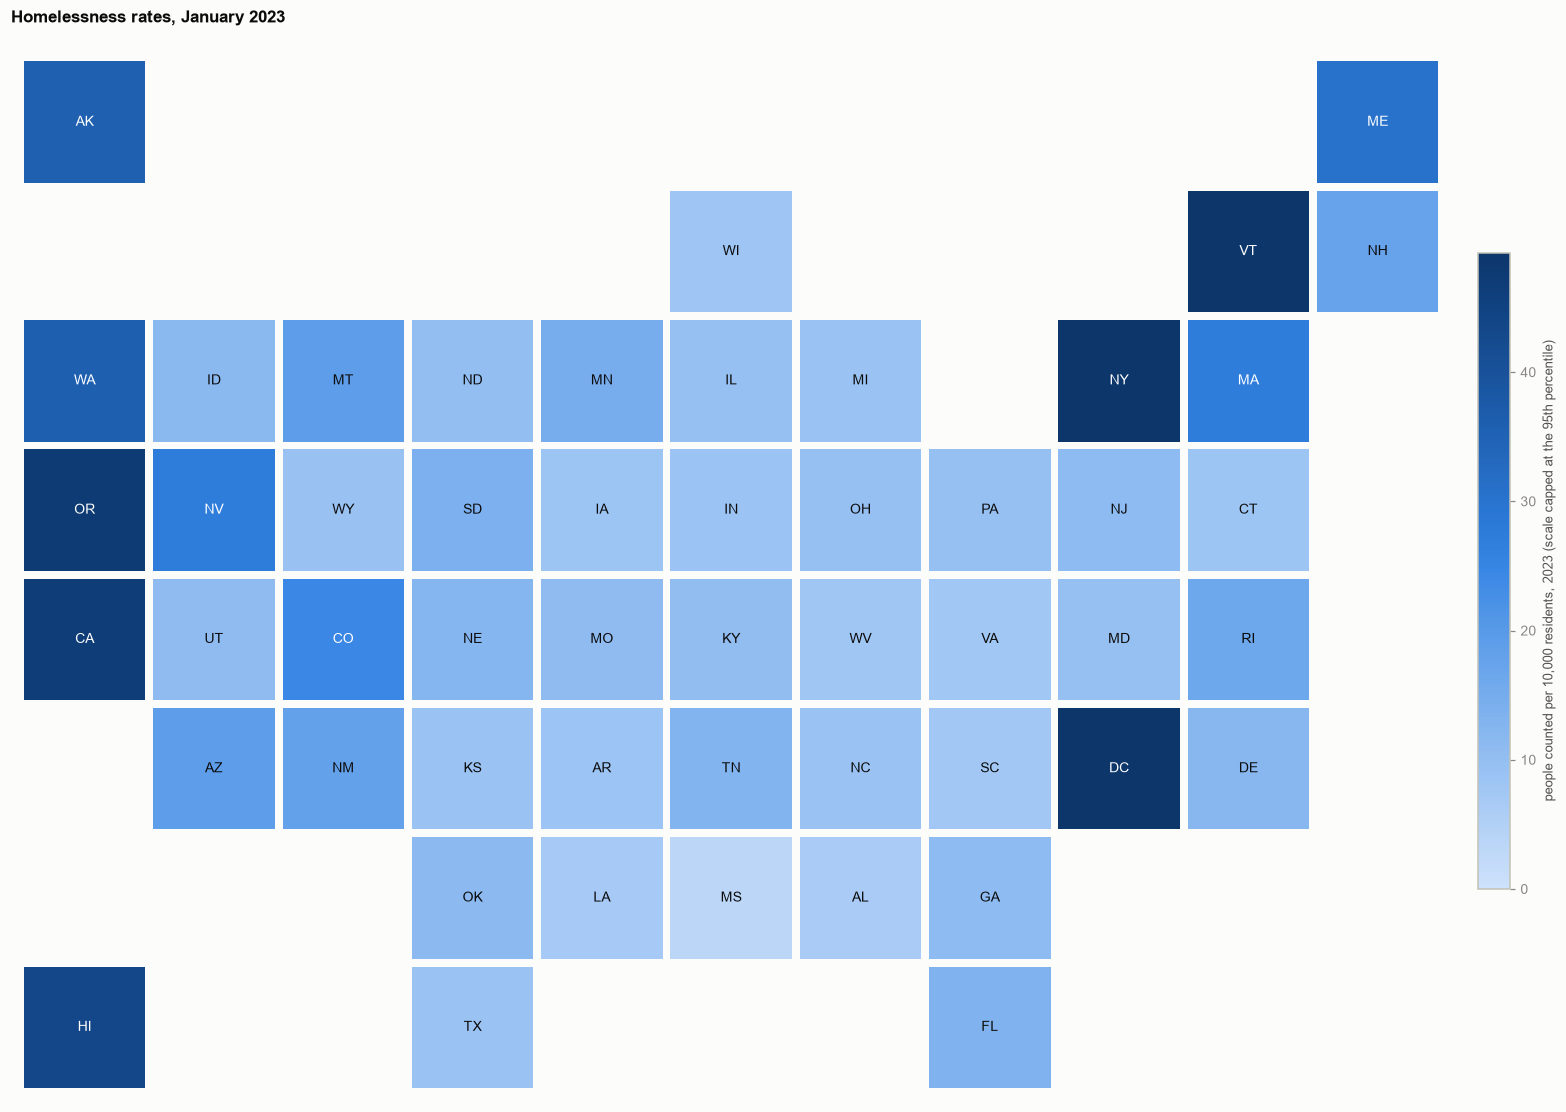

In [8]:
fig, ax = plt.subplots(figsize=(18, 10))
v = d.pit_rate
m_ = tile_map(ax, v, cmap=SEQUENTIAL, vmin=0, vmax=v.quantile(0.95))
cb = fig.colorbar(m_, ax=ax, shrink=0.6, pad=0.01); cb.set_label("people counted per 10,000 residents, 2023 (scale capped at the 95th percentile)", fontsize=8.5)
ax.set_title("Homelessness rates, January 2023", fontsize=11, loc="left")
save_figure(fig, "71_pit_rate_map", part="07_homelessness")
plt.show()

## Findings

**What it can and cannot say.** This section describes the count and its relation to the other measures. It does **not** predict homelessness, and nothing in the 2030 and 2035 scenarios depends on it.

**The count.** People counted on one January night fell from 630,806 in 2010 to 544,084 in 2016, rose to 575,714 in 2020, and then rose steeply: 649,535 in 2023 and 767,856 in 2024 (2021 is incomplete). The change from 2023 to 2024 is +118,321 (18 percent), of which +100,705 is sheltered and +17,616 unsheltered (a floor, since nine states
have incomplete unsheltered counts). Five states account for 76 percent of that national increase: New York (+54,819, +53 percent, almost all sheltered), Illinois (+13,885, +116 percent), Massachusetts (+10,219), California (+5,685), and Hawaii (+5,414, +87 percent); seven states fell. This notebook does not
explain why, and the data here cannot. Chronic homelessness counted rose from 94,344 (2015) to 153,932 (2023) and 167,410 (2024). The highest rates per 10,000 residents in 2023 are DC (72.5), New York (52.7), Vermont (50.9), Oregon (47.6), California (46.6), and Hawaii (43.4); the lowest are Mississippi (3.3), Alabama (6.5), Louisiana (6.9), and
South Carolina (7.5); the median state is 11.1.

**Levels line up with housing costs; nothing in the other need measures adds much.** Across states in 2023 the rate is most strongly related to median gross rent (rank correlation 0.58), then to rent as a share of income (0.37), the rental vacancy rate (-0.36, tighter markets count more), and the need index (0.33 in the direction of higher need; the
printed -0.33 is because rank 1 is the highest need; 0.34 on the 2022-23 mean in Part 1.4). Affordable units per 100 ELI renters (-0.22), the severe burden (0.17), and assisted units per eligible renter (-0.01) are not significantly related, and neither is the **units-at-stake measure of Part 6 (-0.06)**: where the 2035 stake is largest is not where
homelessness is highest today, which is what one would expect from two different questions (a change in the stock, and a measure of acute hardship).

**Changes are not explained at this level.** The cross-state relation is about levels (between states, a 10 percent higher rent goes with about 15 percent higher rate: log rent 1.48, t 2.9, 51 states). Within states, with state and year effects, the rent coefficient is -0.17 (t -0.30) and -0.46 (t -0.82) with vacancy and unemployment,
and -0.24 and -0.49 (t -0.43, -0.85) for sheltered counts alone; income has the wrong sign (+1.47, t 1.82; +2.08, t 2.58 with controls). 654 state-years, 2021 and the nine flagged 2024 states excluded. So annual changes in a state's rent do not predict annual changes in its count in these data, which is why no projection is made. The
plausible reasons are limits of the data, not evidence that rents do not matter: state aggregates hide local markets, a single-night count is noisy, and shelter capacity and counting practices change. A local (continuum-of-care) panel would be the next step.

**Supportive housing.** There are 393,752 permanent supportive housing beds against 153,932 people counted as chronically homeless in 2023 (2.6 beds per person; median state 3.1). States with fewer beds per chronically homeless person have a higher unsheltered share (rank correlation -0.47, p = 0.001); California has the fewest (1.06 beds per person, 68 percent unsheltered), then Oklahoma and Nevada
(1.29) and Oregon (1.32). The ratio is a snapshot, not a need estimate (beds serve people who left homelessness earlier), and small denominators distort it (Connecticut counts 119 chronically homeless people against 7,392 beds). Beds per 10,000 residents correlate with the count (+0.61): capacity sits where homelessness is high, so beds are not a measure of unmet need.

**Caveats.** One night a year; doubled-up households are not counted; 2021 and nine 2024 states are incomplete in the unsheltered count; counts and capacity depend on local counting and reporting practice; states are aggregates of many local systems. Tables are printed above; figures in `outputs/figures/07_homelessness/`.